In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import scvelo as scv

In [2]:
adata=sc.read_h5ad("/home/julia/data/placodes/ANDYs_notebboks/Scenic_neuro_cl6/sub_cl6.h5ad")

In [3]:
adata

AnnData object with n_obs × n_vars = 7153 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'lognorm'
    obsp: 'connectivities', 'distances'

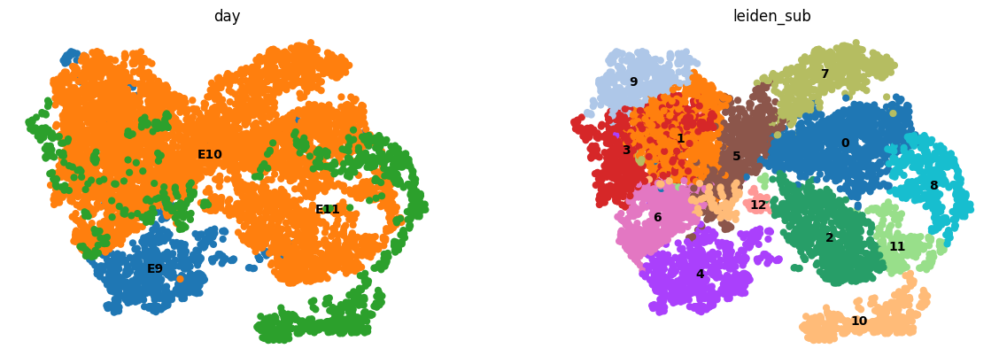

In [4]:
sc.pl.umap(adata, color=['day', 'leiden_sub'],ncols=3, frameon=False, legend_loc="on data", size=140)

In [5]:
adata.uns["log1p"]["base"] = None   # None = натуральный логарифм, стандарт для sc.pp.log1p

In [6]:
sc.tl.leiden(adata, resolution=0.4, key_added="leiden_sub1")

In [7]:
adata.write_h5ad("leiden_sub1_umap.h5ad")

In [8]:
adata=sc.read_h5ad("leiden_sub1_umap.h5ad")

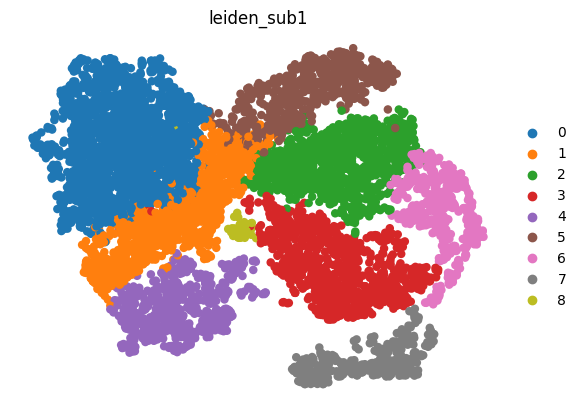

In [9]:
sc.pl.umap(adata,color=[ "leiden_sub1"],frameon=False, save='umap_sub.pdf', size=150)

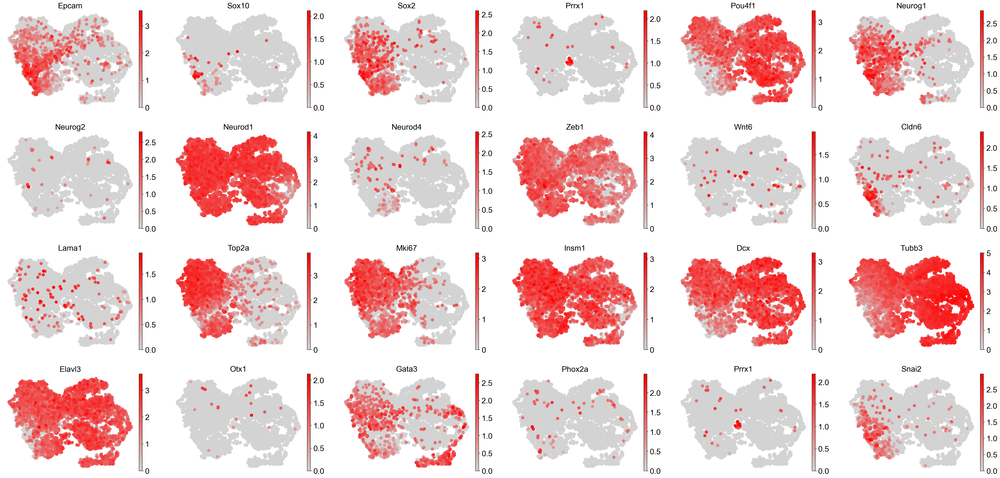

In [10]:
import matplotlib as mpl
from matplotlib.colors import LinearSegmentedColormap

grey_red = LinearSegmentedColormap.from_list("grey_red", ["lightgrey", "red"])
sc.set_figure_params(vector_friendly=True, dpi_save=300, figsize=(6.4, 4.8), fontsize=20)
mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42

sc.pl.umap(
    adata,
    color=["Epcam",'Sox10','Sox2',"Prrx1", "Pou4f1","Neurog1", "Neurog2", "Neurod1", "Neurod4",
           'Zeb1','Wnt6','Cldn6','Lama1', "Top2a", "Mki67", 
    "Insm1", "Dcx", "Tubb3", "Elavl3",  "Otx1", "Gata3","Phox2a","Prrx1", "Snai2"],
    ncols=6,
    cmap=grey_red,
    size=250,
    frameon=False, #save="_Subset2.svg",
)

In [11]:
# Full path to the merged loom file (the file, not just the folder)
merged_loom = "/home/julia/data/placodes/ANDY/loom_all/merged_E8_E11.loom"

# Open the loom as an AnnData object
# cache=True saves a fast-loading copy, so next time it opens in seconds
ldata = scv.read(merged_loom, cache=True)
ldata.var_names_make_unique()  # some gene symbols appear twice

# Quick look
print(ldata)
print("First barcodes:", list(ldata.obs_names[:3]))

AnnData object with n_obs × n_vars = 136387 × 32285
    var: 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    layers: 'ambiguous', 'matrix', 'spliced', 'unspliced'
First barcodes: ['E10_L003_mapped:AAAGGGCGTACAACGGx', 'E10_L003_mapped:AAAGGATGTGTTCCAAx', 'E10_L003_mapped:AAACGAAAGCTCTGTAx']


In [12]:
import re

# ---------------------------------------------------------------
# 1. Lookup table from adata: plate -> suffix  (e.g. "E9_L003" -> "adata1")
# ---------------------------------------------------------------
plate_to_suffix = (adata.obs[["plate", "sample_id"]]
                   .drop_duplicates()
                   .set_index("plate")["sample_id"]
                   .to_dict())
print(plate_to_suffix)   # should show 16 plates

{'E9_L003': 'adata1', 'E9_L004': 'adata2', 'E9_L005': 'adata3', 'E9_L006': 'adata4', 'E10_L003': 'adata5', 'E10_L004': 'adata6', 'E10_L005': 'adata7', 'E10_L006': 'adata8', 'E11_L003': 'adata9', 'E11_L004': 'adata10', 'E11_L005': 'adata11', 'E11_L006': 'adata12'}


In [13]:
# ---------------------------------------------------------------
# 2. Function that converts one velocyto name to adata style
#    "E10_L003_mapped:AAAGGGCGTACAACGGx" -> "AAAGGGCGTACAACGG-1-adata5"
# ---------------------------------------------------------------
def velocyto_to_adata(name):
    sample, barcode = name.split(":")                     # split prefix and barcode
    plate = sample.replace("_mapped", "")                 # "E10_L003"
    plate = re.sub(r"^(E\d+)_(\d+)$", r"\1_L\2", plate)   # fixes E9_003 -> E9_L003
    barcode = barcode.rstrip("x")                         # remove trailing "x"
    suffix = plate_to_suffix.get(plate, "UNMATCHED")      # look up "adataN"
    return f"{barcode}-1-{suffix}"

# ---------------------------------------------------------------
# 3. Keep the original names, then rename
# ---------------------------------------------------------------
ldata.obs["velocyto_name"] = ldata.obs_names
ldata.obs_names = [velocyto_to_adata(n) for n in ldata.obs_names]
print("New barcodes:", list(ldata.obs_names[:3]))

# ---------------------------------------------------------------
# 4. Check how well they match
# ---------------------------------------------------------------
n_shared = len(set(ldata.obs_names) & set(adata.obs_names))
n_unmatched = ldata.obs_names.str.endswith("UNMATCHED").sum()
print(f"Cells in adata:        {adata.n_obs}")
print(f"Cells matched:         {n_shared}")
print(f"Loom cells w/o plate:  {n_unmatched}")

New barcodes: ['AAAGGGCGTACAACGG-1-adata5', 'AAAGGATGTGTTCCAA-1-adata5', 'AAACGAAAGCTCTGTA-1-adata5']
Cells in adata:        7153
Cells matched:         7153
Loom cells w/o plate:  32100


In [14]:
import numpy as np

# 1. Which samples are unmatched? Should be only the four E8 plates
unmatched = ldata.obs_names.str.endswith("UNMATCHED")
print(ldata.obs.loc[unmatched, "velocyto_name"].str.split(":").str[0].value_counts())

# 2. Keep only matched cells (E9-E11)
ldata_e9_11 = ldata[np.array(~unmatched)].copy()

# 3. Names must be unique now
print("Unique names:", ldata_e9_11.obs_names.is_unique)
print("Matched cells:", len(set(ldata_e9_11.obs_names) & set(adata.obs_names)), "of", adata.n_obs)

E8_L004_mapped    8029
E8_L006_mapped    8026
E8_L003_mapped    8025
E8_L005_mapped    8020
Name: velocyto_name, dtype: int64
Unique names: True
Matched cells: 7153 of 7153


AnnData object with n_obs × n_vars = 7153 × 32285
    obs: 'day', 'plate', 'sample_id', 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt', 'doublet_score', 'predicted_doublet', 'doublet_020', 'leiden', 'leiden_1', 'leiden_parent', 'leiden_sub', 'leiden_sub1', 'velocyto_name', 'initial_size_unspliced', 'initial_size_spliced', 'initial_size'
    var: 'gene_ids', 'feature_types', 'genome', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'Accession', 'Chromosome', 'End', 'Start', 'Strand'
    uns: 'day_colors', 'hvg', 'leiden', 'leiden_1', 'leiden_1_colors', 'leiden_colors', 'leiden_parent_colors', 'leiden_sub', 'leiden_sub_colors', 'log1p', 'neighbors', 'pca', 'umap', 'leiden_sub1_colors'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'lognorm', 'ambiguous', 'matrix', 'spliced', 'unspliced'
    obsp: 'con

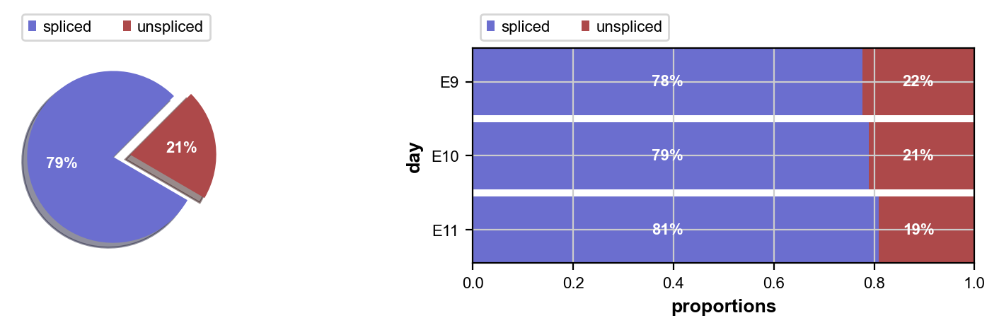

In [15]:
# 4. Merge
adata_vel = scv.utils.merge(adata, ldata_e9_11)
print(adata_vel)
scv.pl.proportions(adata_vel, groupby="day")

# Cell 2: preprocessing for velocity

In [16]:
# Normalize the spliced/unspliced layers and keep the top 2000 genes
scv.pp.filter_and_normalize(adata_vel, min_shared_counts=20, n_top_genes=2000)

# Smooth counts over each cell's neighbors (needed for velocity)
scv.pp.moments(adata_vel, n_pcs=30, n_neighbors=30)

Filtered out 25625 genes that are detected 20 counts (shared).
Normalized count data: spliced, unspliced.
Extracted 2000 highly variable genes.
computing moments based on connectivities
    finished (0:00:00) --> added 
    'Ms' and 'Mu', moments of un/spliced abundances (adata.layers)


# Cell 3: compute velocity

In [17]:
# Estimate velocity for each gene in each cell (stochastic model)
scv.tl.velocity(adata_vel)

# Build the velocity graph: the slowest step with ~125k cells, be patient
scv.tl.velocity_graph(adata_vel, n_jobs=6)   # n_jobs = CPU cores to use

computing velocities
    finished (0:00:01) --> added 
    'velocity', velocity vectors for each individual cell (adata.layers)
computing velocity graph (using 6/32 cores)


  0%|          | 0/7153 [00:00<?, ?cells/s]

    finished (0:00:11) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)


computing velocity embedding
    finished (0:00:02) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


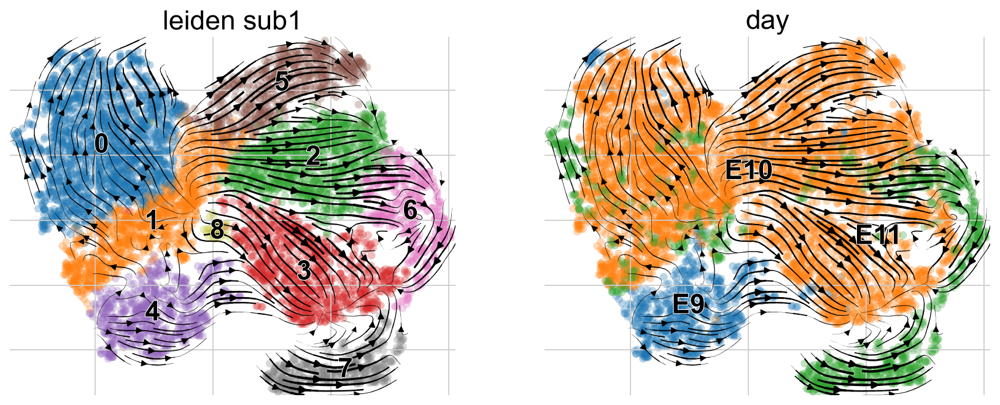

In [18]:
# Velocity arrows on your existing UMAP
scv.pl.velocity_embedding_stream(adata_vel, basis="umap", color=["leiden_sub1", "day"])

# Save so you never have to recompute
#adata_vel.write("/home/julia/data/placodes/ANDYs_notebbooks/h5ad/E8_E11_velocity.h5ad")

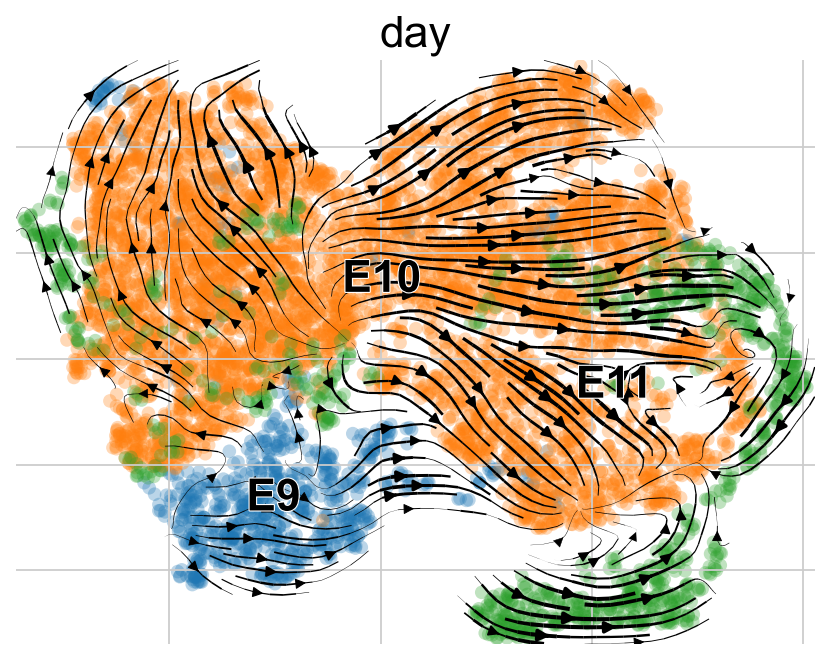

In [20]:
scv.pl.velocity_embedding_stream(adata_vel, basis="umap",  color=[ "day"],size=150,#save='velo1.pdf', legend_loc="right margin"
                                )

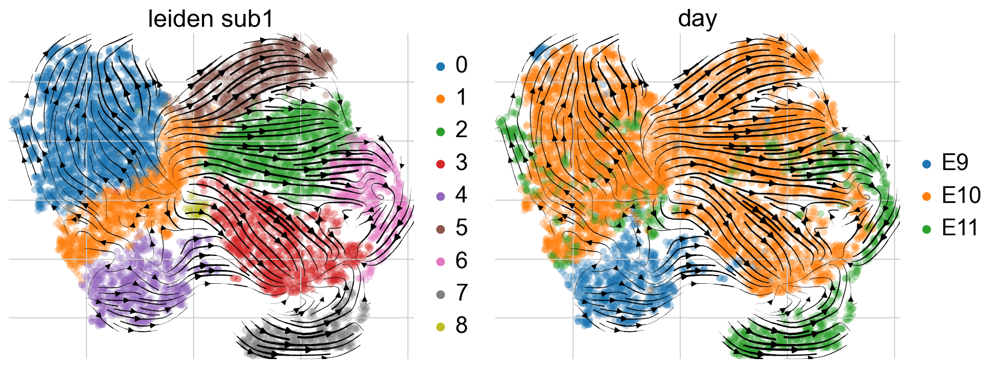

In [21]:
scv.pl.velocity_embedding_stream(adata_vel, basis="umap",  color=["leiden_sub1", "day"],
                                 legend_loc="right margin")

In [22]:
adata_vel.write_h5ad("velocity_E9_11_cl_4_12.h5ad")

In [23]:
adata_vel=sc.read_h5ad("velocity_E9_11_cl_4_12.h5ad")

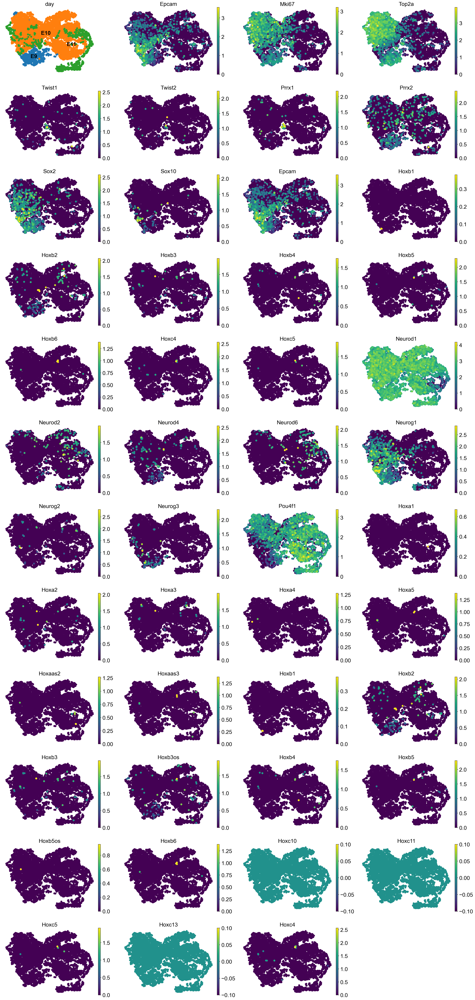

In [24]:
sc.pl.umap( adata, color=['day','Epcam','Mki67','Top2a','Twist1', 'Twist2', 'Prrx1', 'Prrx2', 'Sox2', 'Sox10', 'Epcam', 'Hoxb1', 'Hoxb2', 'Hoxb3', 'Hoxb4', 'Hoxb5', 'Hoxb6', 'Hoxc4', 'Hoxc5', 'Neurod1', 'Neurod2', 'Neurod4', 'Neurod6', 'Neurog1', 'Neurog2', 'Neurog3', 'Pou4f1', 'Hoxa1', 'Hoxa2', 'Hoxa3', 'Hoxa4', 'Hoxa5', 'Hoxaas2', 'Hoxaas3', 'Hoxb1', 'Hoxb2', 'Hoxb3', 'Hoxb3os', 'Hoxb4', 'Hoxb5', 'Hoxb5os', 'Hoxb6', 'Hoxc10', 'Hoxc11', 'Hoxc5', 'Hoxc13', 'Hoxc4', ], frameon=False, legend_loc="on data", size=190 )

In [25]:
scv.tl.recover_dynamics(adata_vel, n_jobs=16)
scv.tl.velocity(adata_vel, mode="dynamical", vkey="velocity_dyn")
print("fit_t" in adata_vel.layers, "velocity_dyn" in adata_vel.layers)

recovering dynamics (using 16/32 cores)


  0%|          | 0/500 [00:00<?, ?gene/s]

    finished (0:00:39) --> added 
    'fit_pars', fitted parameters for splicing dynamics (adata.var)
computing velocities
    finished (0:00:04) --> added 
    'velocity_dyn', velocity vectors for each individual cell (adata.layers)
True True


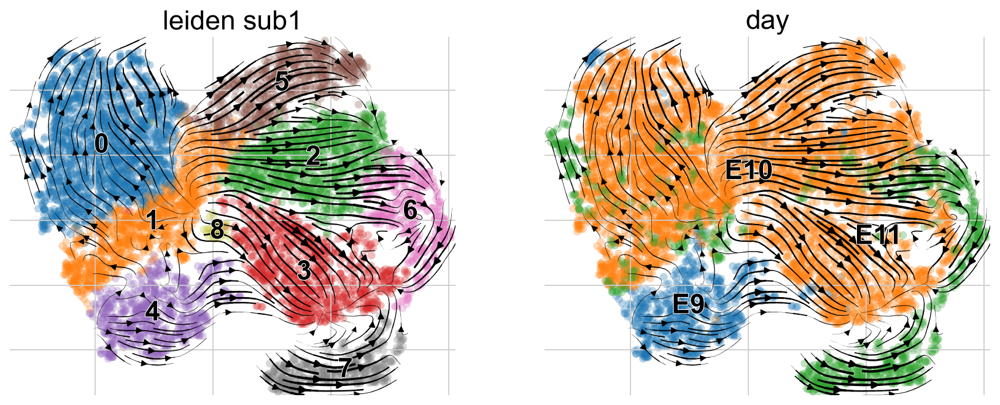

In [26]:
# Velocity arrows on your existing UMAP
scv.pl.velocity_embedding_stream(adata_vel, basis="umap", color=["leiden_sub1", "day"])

In [27]:
adata_vel.write_h5ad("velocity_dynamic_model.h5ad")

In [28]:
adata_vel=sc.read_h5ad("velocity_dynamic_model.h5ad")

Total cells: 7153
Root cells: 660
computing velocity graph (using 16/32 cores)


  0%|          | 0/7153 [00:00<?, ?cells/s]

    finished (0:00:07) --> added 
    'velocity_graph', sparse matrix with cosine correlations (adata.uns)
computing latent time using root_prior as prior
    finished (0:00:01) --> added 
    'latent_time', shared time (adata.obs)


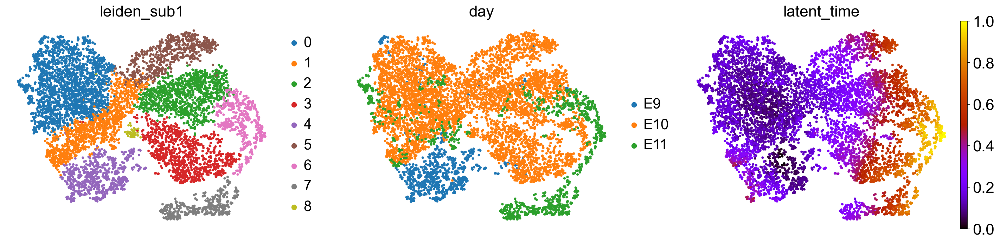

             count   mean  median
leiden_sub1                      
0             1970  0.120   0.118
1             1092  0.152   0.132
4              660  0.158   0.141
8               49  0.199   0.188
2             1029  0.348   0.323
5              607  0.351   0.330
3              923  0.449   0.421
7              368  0.498   0.512
6              455  0.766   0.775


In [29]:
import numpy as np
import scanpy as sc
import scvelo as scv

# 1. Use ALL clusters, root = cluster 1
adata_vel.obs["root_prior"] = (
    adata_vel.obs["leiden_sub1"].astype(str) == "4"
).astype(float)

print("Total cells:", adata_vel.n_obs)
print("Root cells:", int(adata_vel.obs["root_prior"].sum()))

# 2. Compute velocity graph
scv.tl.velocity_graph(adata_vel, vkey="velocity", n_jobs=16)

# 3. Calculate latent time
# Requires dynamical velocity (recover_dynamics + velocity(mode="dynamical"))
scv.tl.latent_time(
    adata_vel,
    vkey="velocity",
    root_key="root_prior",
    min_likelihood=0.2,
    weight_diffusion=0.3
)

# 4. Plot on existing UMAP
sc.pl.umap(
    adata_vel,
    color=["leiden_sub1", "day", "latent_time"],
    cmap="gnuplot",
    frameon=False,
    size=40,
    ncols=3
)

# 5. Mean latent time per cluster
print(
    adata_vel.obs.groupby("leiden_sub1", observed=True)["latent_time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean")
    .round(3)
)

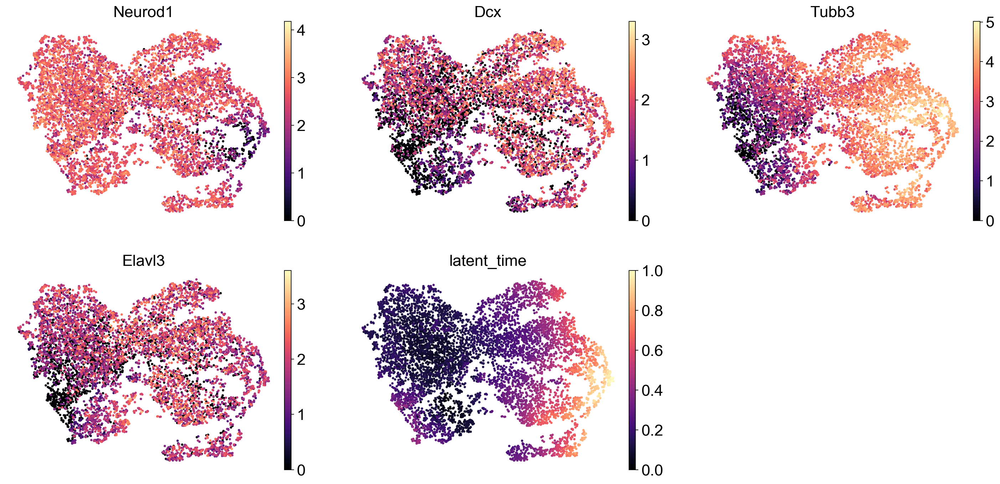

In [30]:
genes = [ "Neurog1", "Neurog2", "Neurod1", "Neurod4", "Insm1", "Dcx", "Tubb3", "Elavl3"]
genes = [g for g in genes if g in adata_vel.var_names]

sc.pl.umap( adata_vel,  color=genes + ["latent_time"], frameon=False, cmap="magma", ncols=3, size=35)

In [31]:
# check what is still in the object
print("velocity layer:", "velocity" in adata_vel.layers)
print("velocity graph:", "velocity_graph" in adata_vel.uns)
print("velocity_umap: ", "velocity_umap" in adata_vel.obsm)

# rebuild what is missing
if "velocity" not in adata_vel.layers:
    scv.tl.velocity(adata_vel, mode="dynamical")    # use the same mode you used before
if "velocity_graph" not in adata_vel.uns:
    scv.tl.velocity_graph(adata_vel)
scv.tl.velocity_embedding(adata_vel, basis="umap")

velocity layer: True
velocity graph: True
velocity_umap:  True
computing velocity embedding
    finished (0:00:01) --> added
    'velocity_umap', embedded velocity vectors (adata.obsm)


/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scvelo/plotting/utils.py:866: MatplotlibDeprecationWarning: Auto-removal of grids by pcolor() and pcolormesh() is deprecated since 3.5 and will be removed two minor releases later; please call grid(False) first.
  cb = pl.colorbar(smp, orientation=orientation, cax=cax)
/home/julia/miniconda3/envs/scanpy/lib/python3.8/site-packages/scvelo/plotting/utils.py:869: MatplotlibDeprecationWarning: The draw_all function was deprecated in Matplotlib 3.6 and will be removed two minor releases later. Use fig.draw_without_rendering() instead.
  cb.draw_all()


figure cannot be saved as pdf, using png instead.
saving figure to file ./figures/scvelo_vel5_1.png


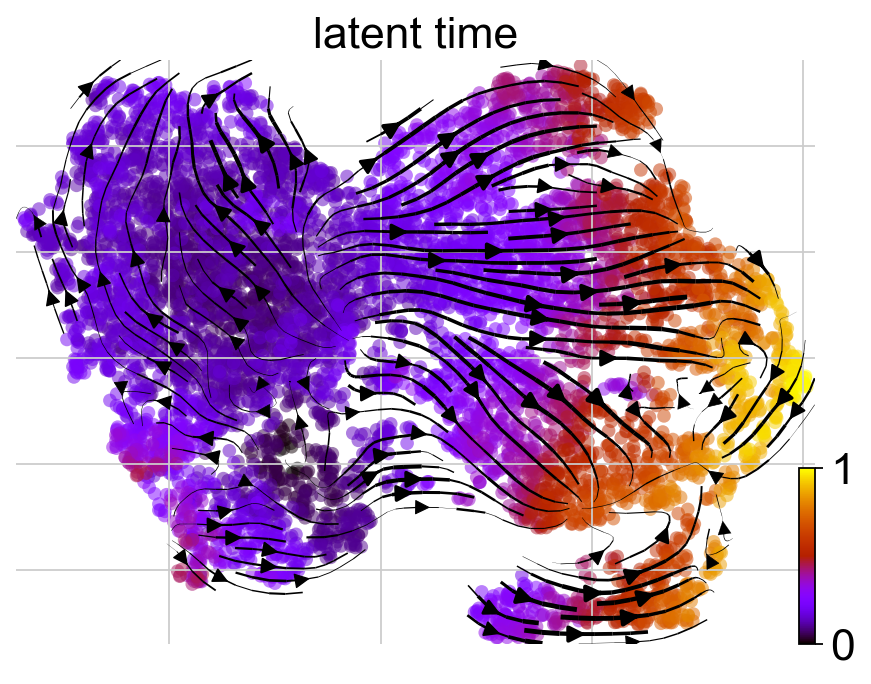

In [32]:
# RNA velocity stream colored by latent time
scv.pl.velocity_embedding_stream(adata_vel,  basis="umap", color="latent_time",  cmap="gnuplot",  vmin=0, vmax=1,  size=150,
   density=1.5,alpha=0.5,  linewidth=1.2,  arrow_size=1.5, frameon=False,save='vel5_1.pdf'
   # title="RNA velocity and latent time", 
)

In [35]:
adata_vel.write_h5ad("velocity_dynamic_model.h5ad")